# 01_ Exploratory Data Analysis (EDA) 

##  Project Overview
This notebook provides an **exploratory data analysis (EDA)** of the anime dataset.
The goal is to understand the structure of the data, check for missing values, explore distributions, 
and gain insights into anime content.

Dataset used:
- `anime.csv` → contains metadata about anime titles, genres, type, episodes, and average ratings.

---

***Import Required Libraries***

In [85]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

##  Loading the Data
We load the anime dataset into Pandas DataFrames and check basic information:
- Shape of the datasets
- Column names
- Data types
- First few rows

In [86]:
DATA_PATH = "../data/raw/anime.csv"
anime_df = pd.read_csv(DATA_PATH)

***lets see the anime dataframe***

In [87]:
anime_df

,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266
...,...,...,...,...,...,...,...
12289,9316,Toushindai My Lover: Minami tai Mecha-Minami,Hentai,OVA,1,4.15,211
12290,5543,Under World,Hentai,OVA,1,4.28,183
12291,5621,Violence Gekiga David no Hoshi,Hentai,OVA,4,4.88,219
12292,6133,Violence Gekiga Shin David no Hoshi: Inma Dens...,Hentai,OVA,1,4.98,175


In [88]:
print("anime dataframe description")
print (anime_df.describe())
print('\n')
print('-'* 60)
print('\n')
print ("anime dataframe information")
print (anime_df.info())

anime dataframe description
           anime_id        rating       members
count  12294.000000  12064.000000  1.229400e+04
mean   14058.221653      6.473902  1.807134e+04
std    11455.294701      1.026746  5.482068e+04
min        1.000000      1.670000  5.000000e+00
25%     3484.250000      5.880000  2.250000e+02
50%    10260.500000      6.570000  1.550000e+03
75%    24794.500000      7.180000  9.437000e+03
max    34527.000000     10.000000  1.013917e+06


------------------------------------------------------------


anime dataframe information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  12294 non-null  int64  
 1   name      12294 non-null  object 
 2   genre     12232 non-null  object 
 3   type      12269 non-null  object 
 4   episodes  12294 non-null  object 
 5   rating    12064 non-null  float64
 6   members   12294 non-nu

Note: `episodes` is currently object type (probably because of "Unknown" values). We'll convert & investigate in the next step.

## Data Cleaning Check
- Identify missing values
- Identify duplicates

In [89]:
print("the missing values")
anime_df.isnull().sum()

the missing values


anime_id      0
name          0
genre        62
type         25
episodes      0
rating      230
members       0
dtype: int64

**Observations:**
- `rating` has 230 missing values (~1.9%)
- `genre` has 62 missing
- `type` has 25 missing

→ We'll decide how to handle them in the preprocessing step.

In [90]:
print("unique values")
anime_df.nunique()

unique values


anime_id    12294
name        12292
genre        3264
type            6
episodes      187
rating        598
members      6706
dtype: int64

In [91]:
anime_df[anime_df.duplicated()]

,anime_id,name,genre,type,episodes,rating,members


**correlation between featurs**

In [92]:
# A statistical measure that shows how two numeric variables move together.
print("correlation between feateares")
anime_df.select_dtypes(include='number').corr()

correlation between feateares


,anime_id,rating,members
anime_id,1.000000,-0.284625,-0.080071
rating,-0.284625,1.000000,0.387979
members,-0.080071,0.387979,1.000000


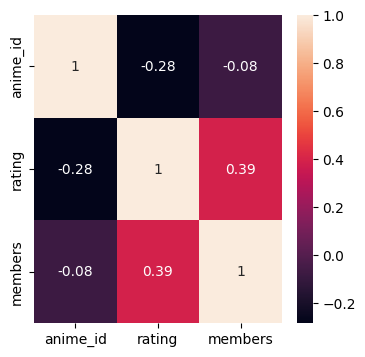

In [93]:
plt.figure(figsize=(4,4))
sns.heatmap(anime_df.select_dtypes(include='number').corr(),annot=True)
plt.show()

**Key observations from correlation:**
- Moderate positive correlation between `rating` and `members` (0.39) → more popular anime (higher members) tend to have slightly higher ratings
- Negative correlation between `anime_id` and `rating` (-0.28) → newer anime IDs tend to have slightly lower average ratings (possible recency effect?)

In [94]:
anime_df.groupby('type').size()

type
Movie      2348
Music       488
ONA         659
OVA        3311
Special    1676
TV         3787
dtype: int64

In [95]:
anime_df.groupby('genre').size()

genre
Action                                                     53
Action, Adventure                                          15
Action, Adventure, Cars, Comedy, Sci-Fi, Shounen            2
Action, Adventure, Cars, Mecha, Sci-Fi, Shounen, Sports     1
Action, Adventure, Cars, Sci-Fi                             1
                                                           ..
Super Power, Supernatural, Vampire                          1
Supernatural                                               14
Thriller                                                    1
Vampire                                                     1
Yaoi                                                        3
Length: 3264, dtype: int64

In [96]:
print("sorting values of the rating")
anime_df.sort_values(by='rating',ascending=False).head(8)

sorting values of the rating


,anime_id,name,genre,type,episodes,rating,members
10464,33662,Taka no Tsume 8: Yoshida-kun no X-Files,"Comedy, Parody",Movie,1,10.00,13
10400,30120,Spoon-hime no Swing Kitchen,"Adventure, Kids",TV,Unknown,9.60,47
9595,23005,Mogura no Motoro,Slice of Life,Movie,1,9.50,62
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
9078,33607,Kahei no Umi,Historical,Movie,1,9.33,44
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262
10786,26313,Yakusoku: Africa Mizu to Midori,"Drama, Kids",OVA,1,9.25,53


In [97]:
print("Top 10 Anime by Number of Members (Popularity) ")
top_popular = anime_df.nlargest(10, 'members')[['name', 'rating', 'members']]
display(top_popular) 

print(" Top 10 Anime by Average Rating ")
top_rated = anime_df.nlargest(10, 'rating')[['name', 'rating', 'members']]
display(top_rated)

Top 10 Anime by Number of Members (Popularity) 


,name,rating,members
40,Death Note,8.71,1013917
86,Shingeki no Kyojin,8.54,896229
804,Sword Art Online,7.83,893100
1,Fullmetal Alchemist: Brotherhood,9.26,793665
159,Angel Beats!,8.39,717796
19,Code Geass: Hangyaku no Lelouch,8.83,715151
841,Naruto,7.81,683297
3,Steins;Gate,9.17,673572
445,Mirai Nikki (TV),8.07,657190
131,Toradora!,8.45,633817


 Top 10 Anime by Average Rating 


,name,rating,members
10464,Taka no Tsume 8: Yoshida-kun no X-Files,10.00,13
10400,Spoon-hime no Swing Kitchen,9.60,47
9595,Mogura no Motoro,9.50,62
0,Kimi no Na wa.,9.37,200630
9078,Kahei no Umi,9.33,44
1,Fullmetal Alchemist: Brotherhood,9.26,793665
2,Gintama°,9.25,114262
10786,Yakusoku: Africa Mizu to Midori,9.25,53
3,Steins;Gate,9.17,673572
4,Gintama&#039;,9.16,151266


checking for skewness 

## Univariate Analysis
- Distribution of numerical features
- Skewness analysis

In [98]:
num_cols = anime_df.select_dtypes(include=np.number).columns

print("Numerical Features:")
print(num_cols)

Numerical Features:
Index(['anime_id', 'rating', 'members'], dtype='object')


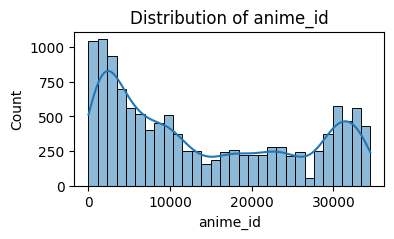

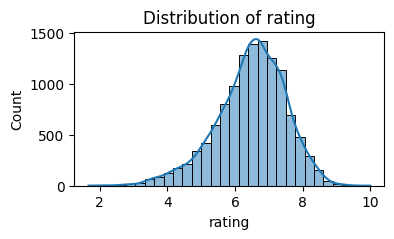

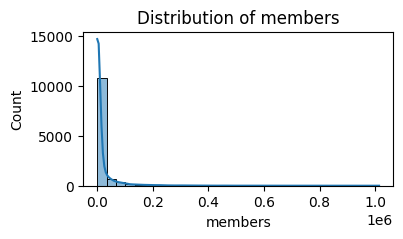

In [99]:
for col in num_cols:
    plt.figure(figsize=(4,2))
    sns.histplot(anime_df[col], bins=30, kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

In [100]:
skew_values = anime_df[num_cols].skew().sort_values(ascending=False)

print("Skewness of Numerical Features:")
print(skew_values)

Skewness of Numerical Features:
members     6.682934
anime_id    0.441550
rating     -0.543570
dtype: float64


we know that 
- |skew| < 0.5 → approximately symmetric
- 0.5 ≤ |skew| < 1 → moderately skewed
- |skew| ≥ 1 → highly skewed

The members feature exhibits skewness, indicating that its distribution is not symmetric and may require a transformation for analysis.

## Multivariate Analysis
- Correlation matrix
- Feature relationships

In [101]:
num_col = anime_df.select_dtypes('int','float')
corr = num_col.corr()
display(corr)

,anime_id,members
anime_id,1.000000,-0.080071
members,-0.080071,1.000000


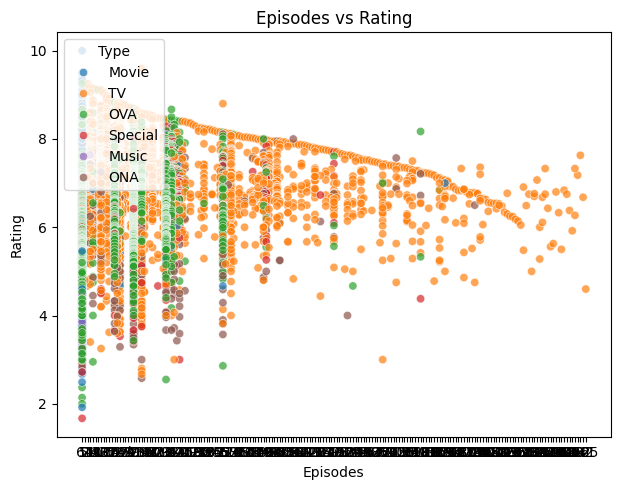

In [102]:
plt.figure(figsize=(12,5))

plt.subplot(1, 2, 2)  
sns.scatterplot(data=anime_df, x='episodes', y='rating', hue='type', alpha=0.7)
plt.title("Episodes vs Rating")
plt.xlabel("Episodes")
plt.ylabel("Rating")
plt.legend(title="Type", loc='upper left')
plt.tight_layout()
plt.show()



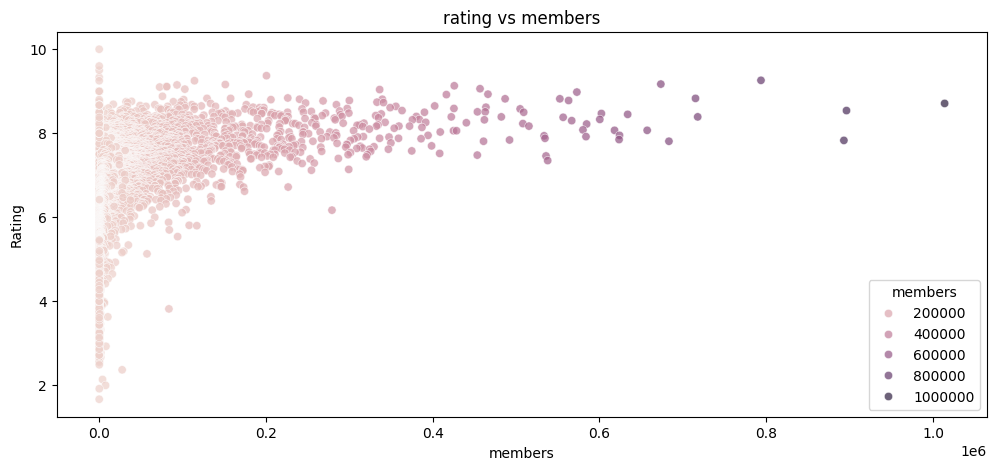

In [103]:
plt.figure(figsize=(12,5))

sns.scatterplot(data=anime_df, x='members', y='rating', hue='members', alpha=0.7)
plt.title("rating vs members")
plt.xlabel("members")
plt.ylabel("Rating")
plt.show()


## Visualizations
- **Rating Distribution:** Histogram of user ratings
- **Anime Popularity:** Distribution of member counts

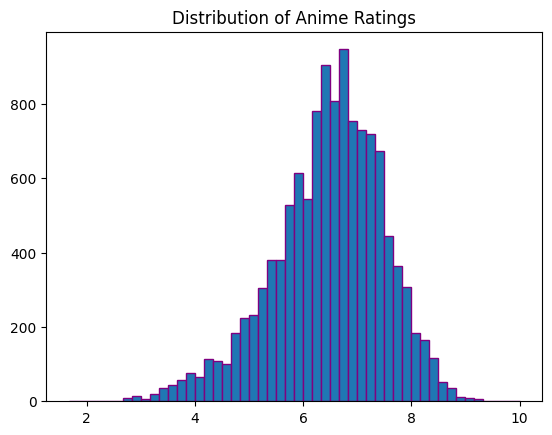

In [104]:
plt.hist(anime_df['rating'] , bins= 50 , edgecolor='purple')
plt.title('Distribution of Anime Ratings')
plt.show()

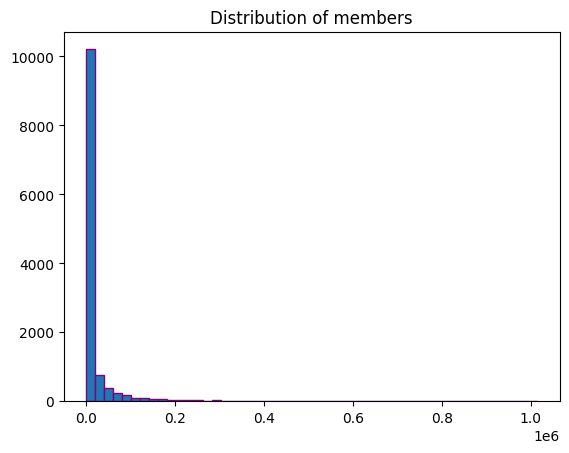

In [105]:
plt.hist(anime_df['members'] , bins= 50 , edgecolor='purple')
plt.title('Distribution of members')
plt.show()

<Axes: >

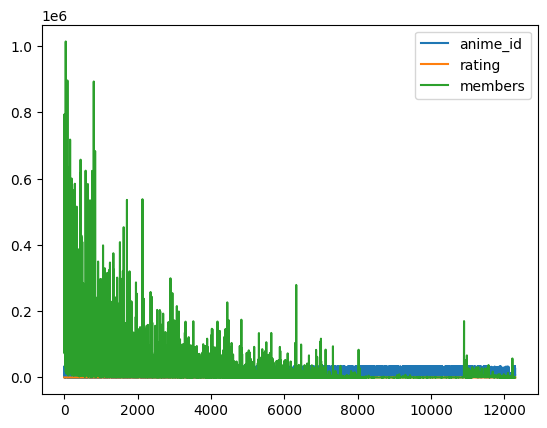

In [106]:
anime_df.plot()

<Axes: >

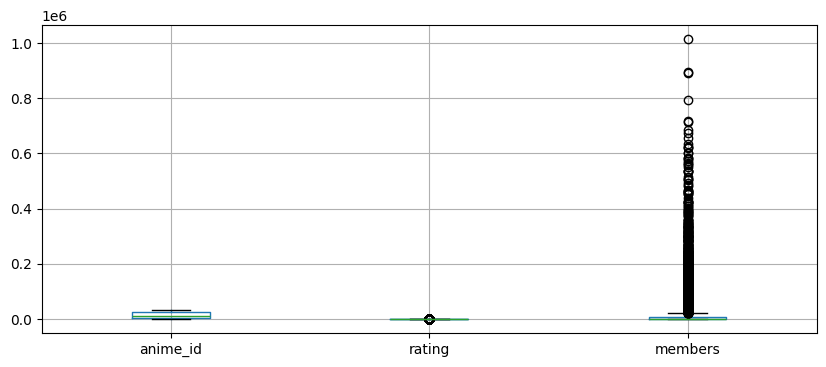

In [107]:
anime_df.boxplot(figsize=(10,4))


### Next Steps
Based on the EDA, the next two steps will include:
- Data preprocessing and cleaning
- Feature engineering (e.g., encoding genres, type)